# LSTM backtesting — figures and results table

The counterpart of the iTransformer backtesting-diagrams notebook. It reads the
trade logs written by `02_lstm_backtesting.ipynb` and produces:

* one figure per strategy, uptrend against sideways, with all four feature sets
  and a buy-and-hold reference (the LSTM versions of `output1/2/3.png`);
* the backtesting metrics table across every strategy / feature set / regime
  combination, with the same metric definitions as the manuscript table;
* a LaTeX drop-in for that table, and the per-regime BTC price moves.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import lstm_common as L

warnings.filterwarnings("ignore")
pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)

# Figure style, palette and layout live in lstm_common.py. Nothing
# figure-related is redeclared here, so the LSTM and iTransformer figures cannot
# drift from each other.
STRATEGIES = L.BT_STRATEGIES
FILE_PREFIX = L.BT_FILE_PREFIX
MARKETS = L.BT_MARKETS
COLORS = L.BT_PALETTE

# '-1' is the first validation period, '-2' the second, as written by the
# backtesting notebooks
PERIOD_OF = {"uptrend": 1, "sideways": 2}
FOLDERS = [L.FOLDER_NAME[n] for n in L.FEATURE_SET_ORDER]
FOLDER_TO_NAME = {v: k for k, v in L.FOLDER_NAME.items()}
INITIAL_CAPITAL = L.INITIAL_CAPITAL


def load_trades(folder, strategy, market):
    return L.load_trade_log(L.BT_DIR, folder, strategy, market)


print("feature-set folders:", FOLDERS)


feature-set folders: ['price_only', 'sentiment_only', 'technicals_only', 'full_dataset']


## 1. Reference BTC price

Taken from the hourly `close` column of the price+volume feature set built for
the backtesting stage, i.e. the exact series the backtests trade on.

price+volume               variates= 4  rows=71,857  (cache)
price+volume+sentiment     variates= 5  rows=59,815  (cache)
price+volume+technicals    variates=10  rows=52,339  (cache)
full                       variates=11  rows=52,339  (cache)
BTC hourly close: 71,857 rows, 2017-08-17 05:00:00+00:00 -> 2025-11-02 12:00:00+00:00


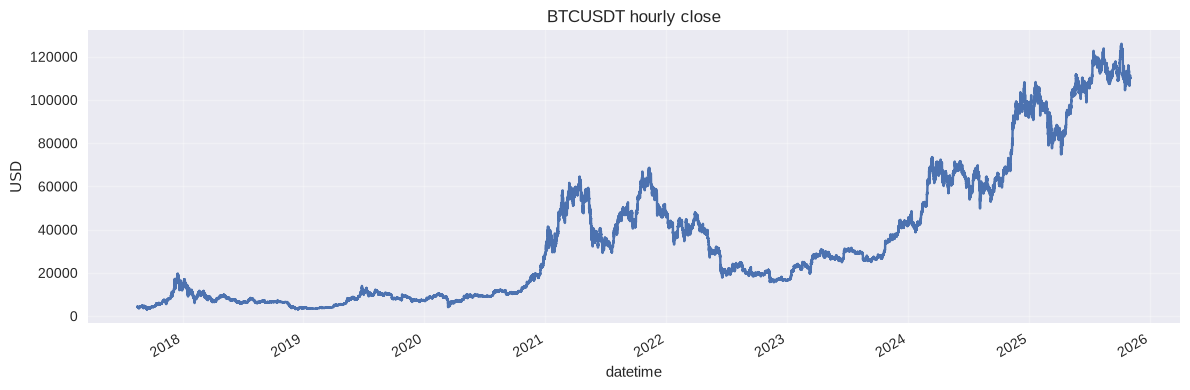

In [2]:
HOURLY = L.build_feature_sets(L.SENT_FILE_BACKTEST)
btc = HOURLY["price+volume"][["close"]].copy()
btc.index.name = "datetime"
print(f"BTC hourly close: {len(btc):,} rows, {btc.index.min()} -> {btc.index.max()}")

fig, ax = plt.subplots(figsize=(12, 4))
btc["close"].plot(ax=ax, title="BTCUSDT hourly close")
ax.set_ylabel("USD")
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

## 2. Portfolio trajectories per strategy

Each figure holds the two regimes side by side; every feature set is one line,
and the grey line is buy-and-hold rebased to the same starting capital.

Threshold Strategy: uptrend (left) vs sideways (right)  ->  lstm_output1.png


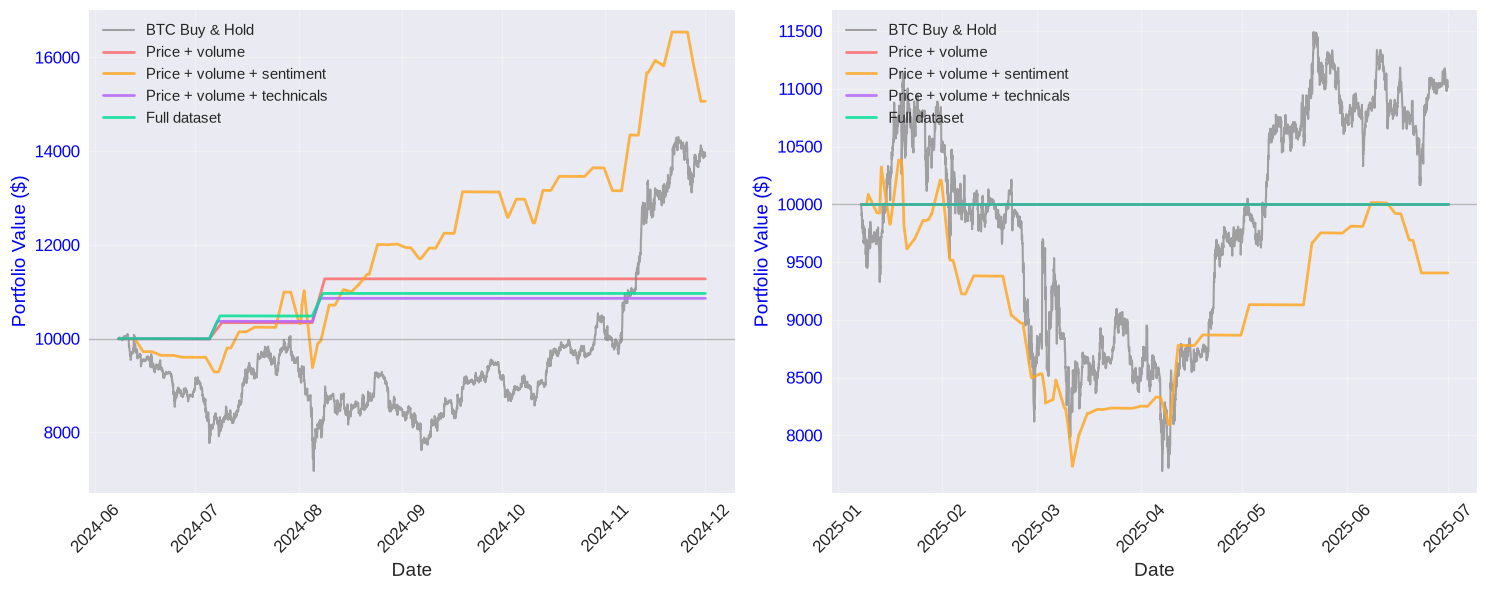

Risk-Based Strategy: uptrend (left) vs sideways (right)  ->  lstm_output2.png


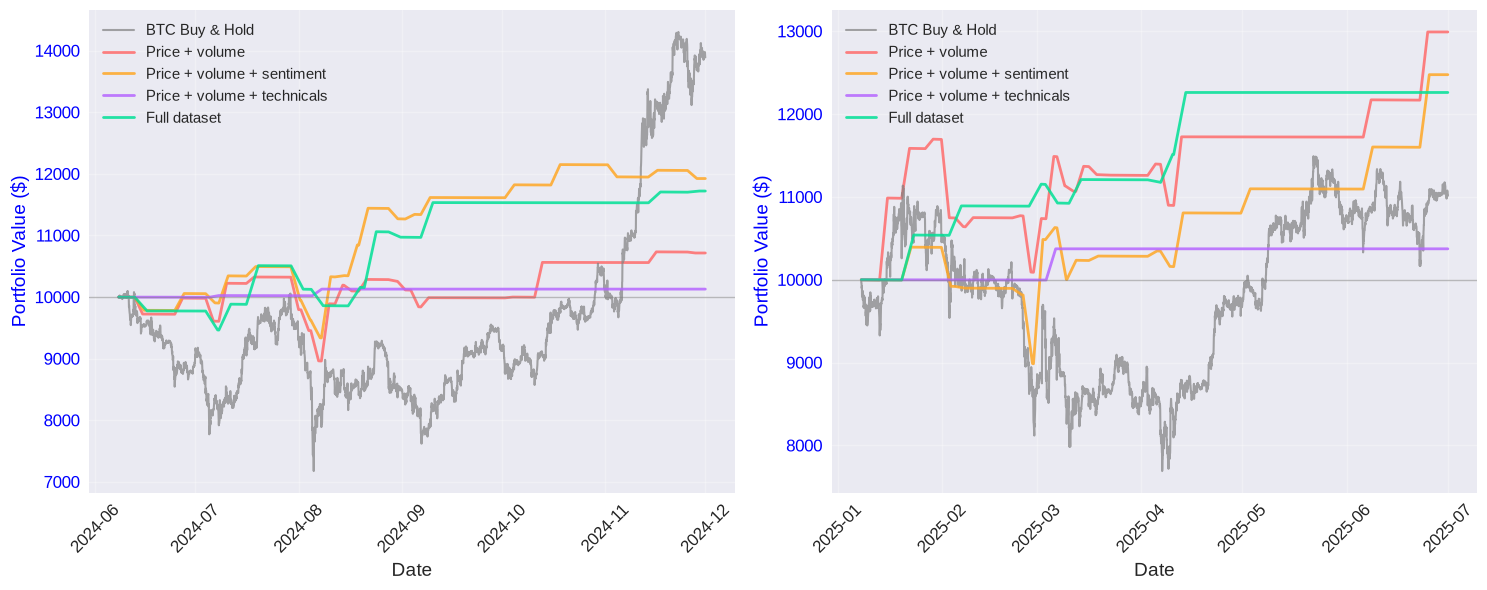

Momentum Strategy: uptrend (left) vs sideways (right)  ->  lstm_output3.png


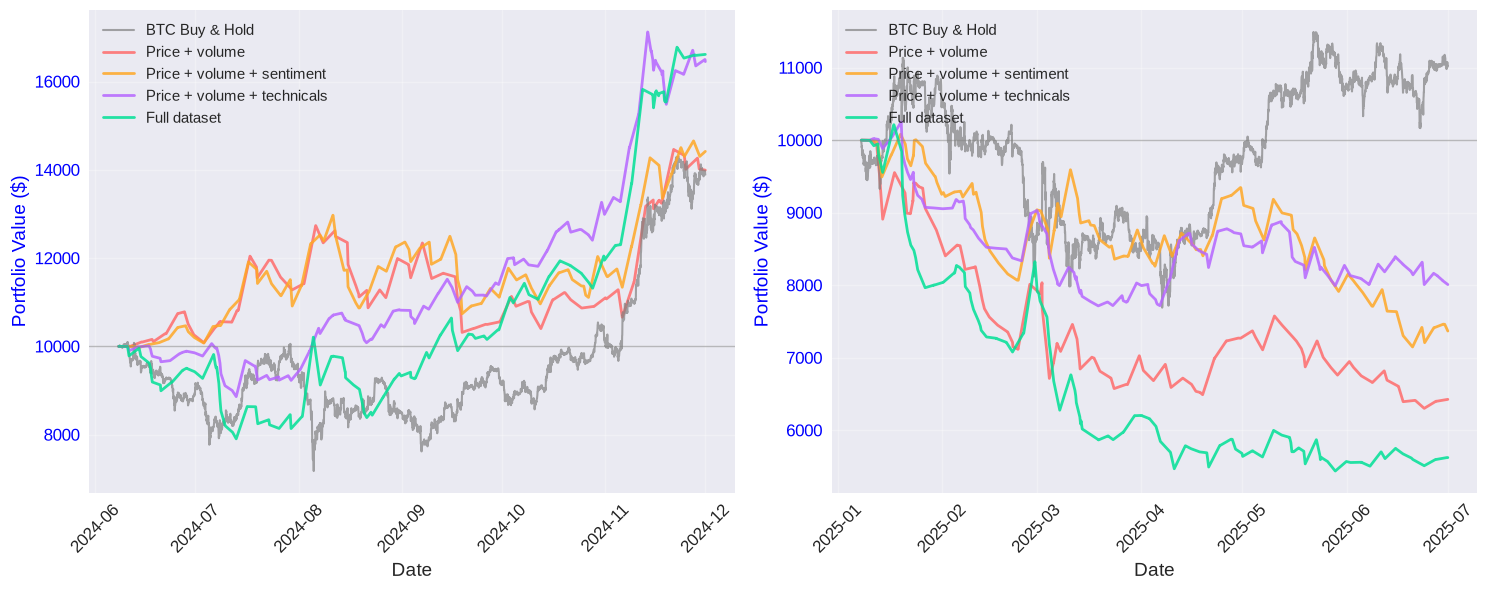

In [3]:
FIGURE_FILE = {"threshold": "lstm_output1.png",
               "risk_based": "lstm_output2.png",
               "momentum": "lstm_output3.png"}

# Layout and palette come from L.plot_portfolio_panels in lstm_common.py.
# Declaring them here again is how the two model families would drift apart.
for strategy, strategy_name in L.BT_STRATEGIES.items():
    L.plot_portfolio_panels(L.BT_DIR, btc["close"], strategy,
                            save_to=L.OUT / FIGURE_FILE[strategy])
    print(f"{strategy_name}: uptrend (left) vs sideways (right)  ->  "
          f"{FIGURE_FILE[strategy]}")
    plt.show()


## 3. Metrics

Definitions are the ones used for the manuscript's backtesting table: metrics
are computed on the trade-level portfolio series, so a "trade" is a row of the
trade log, the win rate is the share of positive step-to-step returns in that
series, the drawdown is the deepest peak-to-trough fall of it, and the Sharpe
column is the unannualised mean/standard-deviation ratio of its returns.

`Entries` counts how many positions were actually opened. A run that never
opened one still has a two-row trade log (`start` and `end`), so it scores a
0.00 % drawdown and an undefined Sharpe — flat because it never traded, not
because it traded well. Those runs are reported as zeros and are excluded from
the best-value comparison in the LaTeX table below.

In [4]:
def summarize_trades(portfolio_values):
    pv = pd.Series(portfolio_values).astype(float)
    trade_returns = pv.pct_change().dropna()
    wins = int((trade_returns > 0).sum())
    evaluated = len(trade_returns)
    win_rate = (wins / evaluated) * 100 if evaluated else float("nan")
    return len(pv), wins, win_rate


metrics = []
for folder in FOLDERS:
    name = FOLDER_TO_NAME[folder]
    for strategy, strategy_name in STRATEGIES.items():
        for market, info in MARKETS.items():
            tdf = load_trades(folder, strategy, market)
            if tdf is None:
                continue
            pv = tdf["portfolio_value"]
            returns = pv.pct_change().dropna()
            trade_count, wins, win_rate = summarize_trades(pv)
            entries = int(tdf["trade_type"].isin(["long", "short"]).sum())
            final_value = float(pv.iloc[-1]) if len(pv) else float("nan")
            initial_value = float(pv.iloc[0]) if len(pv) else float("nan")
            returns_pct = ((final_value - initial_value) / initial_value * 100
                           if initial_value else float("nan"))
            metrics.append({
                "Dataset": L.NICE_NAME[name],
                "Strategy": strategy_name,
                "Market": info["label"],
                "Trades": trade_count,
                "Profitable Trades": wins,
                "Win Rate (%)": win_rate,
                "Max Drawdown (%)": abs(L.calculate_max_drawdown(pv)) * 100,
                "Simple Sharpe": L.simple_sharpe_ratio(returns),
                "Final Value": final_value,
                "Returns (%)": returns_pct,
                "Entries": entries,
                "folder_key": folder, "strategy_key": strategy, "market_key": market,
            })

metrics_df = pd.DataFrame(metrics)
metrics_df = metrics_df.sort_values(["Strategy", "Market", "Dataset"]).reset_index(drop=True)
metrics_df.drop(columns=[c for c in metrics_df.columns if c.endswith("_key")]) \
    .to_csv(L.OUT / "lstm_backtesting_metrics.csv", index=False)
display(metrics_df.drop(columns=[c for c in metrics_df.columns if c.endswith("_key")])
        .round({"Win Rate (%)": 2, "Max Drawdown (%)": 2, "Simple Sharpe": 3,
                "Final Value": 0, "Returns (%)": 2}))

,Dataset,Strategy,Market,Trades,Profitable Trades,Win Rate (%),Max Drawdown (%),Simple Sharpe,Final Value,Returns (%),Entries
0,Full dataset,Momentum Strategy,Sideways Market,208,29,14.01,46.75,-0.126,5624.0,-43.76,103
1,Price + volume,Momentum Strategy,Sideways Market,181,27,15.00,36.97,-0.100,6427.0,-35.73,90
2,Price + volume + sentiment,Momentum Strategy,Sideways Market,205,33,16.18,29.08,-0.073,7369.0,-26.31,102
3,Price + volume + technicals,Momentum Strategy,Sideways Market,255,36,14.17,24.73,-0.062,8010.0,-19.90,127
4,Full dataset,Momentum Strategy,Uptrend Market,201,41,20.50,20.95,0.101,16615.0,66.15,100
5,Price + volume,Momentum Strategy,Uptrend Market,153,37,24.34,19.00,0.094,13994.0,39.94,76
6,Price + volume + sentiment,Momentum Strategy,Uptrend Market,167,43,25.90,17.22,0.104,14418.0,44.18,83
7,Price + volume + technicals,Momentum Strategy,Uptrend Market,231,50,21.74,11.93,0.129,16452.0,64.52,115
8,Full dataset,Risk-Based Strategy,Sideways Market,18,6,35.29,2.07,0.555,12261.0,22.61,8
9,Price + volume,Risk-Based Strategy,Sideways Market,42,12,29.27,13.74,0.207,12992.0,29.92,20


## 4. Buy-and-hold reference per regime

In [5]:
bh_rows = []
for market, info in MARKETS.items():
    ref = load_trades(FOLDERS[-1], "threshold", market)
    start, end = ref["datetime"].min(), ref["datetime"].max()
    sub = btc[(btc.index >= start) & (btc.index <= end)]
    p0, p1 = float(sub["close"].iloc[0]), float(sub["close"].iloc[-1])
    bh_rows.append(dict(market=info["label"], start=start, end=end,
                        btc_start=p0, btc_end=p1, btc_change_pct=100 * (p1 - p0) / p0,
                        buy_hold_final=INITIAL_CAPITAL * p1 / p0))
bh = pd.DataFrame(bh_rows)
bh.to_csv(L.OUT / "lstm_buy_and_hold.csv", index=False)
print(bh.to_string(index=False, float_format=lambda v: f"{v:,.2f}"))
BH = dict(zip(bh["market"], bh["buy_hold_final"]))

         market                     start                       end  btc_start    btc_end  btc_change_pct  buy_hold_final
 Uptrend Market 2024-06-08 00:00:00+00:00 2024-11-30 23:00:00+00:00  69,401.50  96,407.99           38.91       13,891.34
Sideways Market 2025-01-08 01:00:00+00:00 2025-06-30 23:00:00+00:00  96,907.15 107,146.50           10.57       11,056.61


## 5. Backtesting results table — LaTeX

Same layout as the manuscript's table: strategies as row groups, regimes as the
two blocks, bold marking the best model-based value per metric within a block,
buy-and-hold in italics.

In [6]:
STRAT_TEX = {"threshold": "Threshold",
             "risk_based": "Volatility-adjusted",
             "momentum": "Momentum"}

lines = [
    r"\begin{table}[H]", r"\footnotesize",
    r"\caption{LSTM backtesting results across all strategies and market regimes.}",
    r"\label{tab:lstm_all_backtesting_results}", "",
    r"\begin{adjustwidth}{-\extralength}{0cm}", r"\begin{threeparttable}",
    r"\renewcommand{\arraystretch}{1.08}", r"\setlength{\tabcolsep}{4pt}", "",
    r"\begin{tabularx}{\fulllength}{",
    r">{\raggedright\arraybackslash}m{2.4cm}",
    r">{\raggedright\arraybackslash}m{4.0cm}",
    r">{\raggedleft\arraybackslash}m{1.2cm}",
    r">{\raggedleft\arraybackslash}m{1.4cm}",
    r">{\raggedleft\arraybackslash}m{1.3cm}",
    r">{\raggedleft\arraybackslash}m{1.7cm}",
    r">{\raggedleft\arraybackslash}m{1.2cm}",
    r">{\raggedleft\arraybackslash}m{1.6cm}",
    r"}", r"\toprule",
    r"\textbf{Strategy} & \textbf{Feature set} & \textbf{Trades} & "
    r"\textbf{Profitable} & \textbf{WR (\%)} & \textbf{Max DD (\%)} & "
    r"\textbf{Sharpe} & \textbf{Final (\$)} \\", r"\midrule",
]


def fmt(v, spec, best=False):
    s = f"{v:{spec}}"
    if s.startswith("-"):
        s = "$-$" + s[1:]
    return rf"\textbf{{{s}}}" if best else s


for mi, (market, info) in enumerate(MARKETS.items()):
    brow = bh[bh["market"] == info["label"]].iloc[0]
    period = f"{brow['start']:%b %Y} -- {brow['end']:%b %Y}"
    if mi:
        lines.append(r"\midrule")
    lines.append(rf"\multicolumn{{8}}{{c}}{{\textit{{{info['label']} Period "
                 rf"({period})}}}} \\")
    lines.append(r"\midrule")

    for si, strategy in enumerate(STRATEGIES):
        block = metrics_df[(metrics_df["strategy_key"] == strategy) &
                           (metrics_df["market_key"] == market)]
        # a run that never opened a position is flat by construction: its 0.00%
        # drawdown and undefined Sharpe must not win the comparison
        traded = block[block["Entries"] > 0]
        best_wr = traded["Win Rate (%)"].max() if len(traded) else None
        best_dd = traded["Max Drawdown (%)"].min() if len(traded) else None
        best_sh = traded["Simple Sharpe"].max() if len(traded) else None
        best_fv = traded["Final Value"].max() if len(traded) else None

        lines.append(rf"\multirow{{5}}{{*}}{{{STRAT_TEX[strategy]}}}")
        for name in L.FEATURE_SET_ORDER:
            r = block[block.Dataset == L.NICE_NAME[name]]
            if not len(r):
                continue
            r = r.iloc[0]
            if r["Entries"] == 0:
                lines.append(
                    rf"& {L.NICE_NAME[name]:28s} & \textit{{0}} & \textit{{0}} & "
                    rf"\textit{{0.00}} & \textit{{0.00}} & \textit{{0.000}} & "
                    rf"\textit{{{r['Final Value']:,.0f}}} \\")
                continue
            lines.append(
                f"& {L.NICE_NAME[name]:28s} & {int(r['Trades'])} & "
                f"{int(r['Profitable Trades'])} & "
                f"{fmt(r['Win Rate (%)'], '.2f', r['Win Rate (%)'] == best_wr)} & "
                f"{fmt(r['Max Drawdown (%)'], '.2f', r['Max Drawdown (%)'] == best_dd)} & "
                f"{fmt(r['Simple Sharpe'], '.3f', r['Simple Sharpe'] == best_sh)} & "
                f"{fmt(r['Final Value'], ',.0f', r['Final Value'] == best_fv)} \\\\")
        lines.append(rf"& \textit{{Buy-and-hold}} & \textit{{--}} & \textit{{--}} & "
                     rf"\textit{{--}} & \textit{{--}} & \textit{{--}} & "
                     rf"\textit{{{BH[info['label']]:,.0f}}} \\")
        if si < len(STRATEGIES) - 1:
            lines.append(r"\addlinespace")

lines += [
    r"\bottomrule", r"\end{tabularx}", "",
    r"\begin{tablenotes}[flushleft]", r"\footnotesize",
    r"\item \textit{Note:} Signals come from the LSTM forecasters of "
    r"Table~\ref{tab:lstm_forecasting_performance_results}; strategy parameters "
    r"were tuned on the training period only, by 10-fold chronological "
    r"cross-validation with Optuna. Within each strategy and market regime, bold "
    r"values denote the best model-based result in the corresponding metric "
    r"column. For maximum drawdown, lower values are better. Buy-and-hold is "
    r"shown in italics as a benchmark. WR is computed over evaluable closed "
    r"trades only. Rows shown entirely in italics are runs in which the "
    r"CV-selected entry threshold was never crossed, so no position was opened; "
    r"they are excluded from the best-value comparison, since their zero "
    r"drawdown reflects inactivity rather than risk control.",
    r"\end{tablenotes}", r"\end{threeparttable}", r"\end{adjustwidth}",
    r"\end{table}"]

tex_bt = "\n".join(lines)
(L.OUT / "table_lstm_backtesting.tex").write_text(tex_bt)
print(tex_bt)

\begin{table}[H]
\footnotesize
\caption{LSTM backtesting results across all strategies and market regimes.}
\label{tab:lstm_all_backtesting_results}

\begin{adjustwidth}{-\extralength}{0cm}
\begin{threeparttable}
\renewcommand{\arraystretch}{1.08}
\setlength{\tabcolsep}{4pt}

\begin{tabularx}{\fulllength}{
>{\raggedright\arraybackslash}m{2.4cm}
>{\raggedright\arraybackslash}m{4.0cm}
>{\raggedleft\arraybackslash}m{1.2cm}
>{\raggedleft\arraybackslash}m{1.4cm}
>{\raggedleft\arraybackslash}m{1.3cm}
>{\raggedleft\arraybackslash}m{1.7cm}
>{\raggedleft\arraybackslash}m{1.2cm}
>{\raggedleft\arraybackslash}m{1.6cm}
}
\toprule
\textbf{Strategy} & \textbf{Feature set} & \textbf{Trades} & \textbf{Profitable} & \textbf{WR (\%)} & \textbf{Max DD (\%)} & \textbf{Sharpe} & \textbf{Final (\$)} \\
\midrule
\multicolumn{8}{c}{\textit{Uptrend Market Period (Jun 2024 -- Nov 2024)}} \\
\midrule
\multirow{5}{*}{Threshold}
& Price + volume               & 6 & 2 & \textbf{40.00} & 0.03 & 0.702 & 11,276 \\
& Pr

## 6. Summary

In [7]:
print("=" * 78)
print("LSTM BACKTESTING — SUMMARY")
print("=" * 78)
for market, info in MARKETS.items():
    print(f"\n{info['label']}  (buy-and-hold ${BH[info['label']]:,.0f})")
    for strategy, sname in STRATEGIES.items():
        block = metrics_df[(metrics_df["strategy_key"] == strategy) &
                           (metrics_df["market_key"] == market)]
        beat = block[block["Final Value"] > BH[info["label"]]]
        print(f"  {sname:22s} best ${block['Final Value'].max():9,.0f} "
              f"({block.loc[block['Final Value'].idxmax(), 'Dataset']}), "
              f"{len(beat)}/{len(block)} beat buy-and-hold")

print("\nFigures:", ", ".join(FIGURE_FILE.values()))
print("Tables :  lstm_backtesting_metrics.csv, table_lstm_backtesting.tex")
print("All artefacts in", L.OUT)

LSTM BACKTESTING — SUMMARY

Uptrend Market  (buy-and-hold $13,891)
  Threshold Strategy     best $   15,063 (Price + volume + sentiment), 1/4 beat buy-and-hold
  Risk-Based Strategy    best $   11,925 (Price + volume + sentiment), 0/4 beat buy-and-hold
  Momentum Strategy      best $   16,615 (Full dataset), 4/4 beat buy-and-hold

Sideways Market  (buy-and-hold $11,057)
  Threshold Strategy     best $   10,000 (Full dataset), 0/4 beat buy-and-hold
  Risk-Based Strategy    best $   12,992 (Price + volume), 3/4 beat buy-and-hold
  Momentum Strategy      best $    8,010 (Price + volume + technicals), 0/4 beat buy-and-hold

Figures: lstm_output1.png, lstm_output2.png, lstm_output3.png
Tables :  lstm_backtesting_metrics.csv, table_lstm_backtesting.tex
All artefacts in /home/kosmo/Documents/Magis-submit/src-vibe (Copy)/lstm_models/out
